In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [2]:
print(tf.__version__)

2.21.0


In [3]:
df=pd.read_csv("customer_churn_dataset.csv")

In [4]:
df.shape

(64374, 12)

In [5]:
df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0


In [6]:
df.tail()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
64369,64370,45,Female,33,12,6,21,Basic,Quarterly,947,14,1
64370,64371,37,Male,6,1,5,22,Standard,Annual,923,9,1
64371,64372,25,Male,39,14,8,30,Premium,Monthly,327,20,1
64372,64373,50,Female,18,19,7,22,Standard,Monthly,540,13,1
64373,64374,52,Female,45,15,9,25,Standard,Monthly,696,22,1


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64374 entries, 0 to 64373
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   CustomerID         64374 non-null  int64 
 1   Age                64374 non-null  int64 
 2   Gender             64374 non-null  object
 3   Tenure             64374 non-null  int64 
 4   Usage Frequency    64374 non-null  int64 
 5   Support Calls      64374 non-null  int64 
 6   Payment Delay      64374 non-null  int64 
 7   Subscription Type  64374 non-null  object
 8   Contract Length    64374 non-null  object
 9   Total Spend        64374 non-null  int64 
 10  Last Interaction   64374 non-null  int64 
 11  Churn              64374 non-null  int64 
dtypes: int64(9), object(3)
memory usage: 5.9+ MB


In [8]:
df.columns.to_list()

['CustomerID',
 'Age',
 'Gender',
 'Tenure',
 'Usage Frequency',
 'Support Calls',
 'Payment Delay',
 'Subscription Type',
 'Contract Length',
 'Total Spend',
 'Last Interaction',
 'Churn']

In [9]:
df.describe()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000
mean,32187.500000,41.970982,31.994827,15.080234,5.400690,17.133952,541.023379,15.498850,0.473685
std,18583.317451,13.924911,17.098234,8.816470,3.114005,8.852211,260.874809,8.638436,0.499311
min,1.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,16094.250000,30.000000,18.000000,7.000000,3.000000,10.000000,313.000000,8.000000,0.000000
50%,32187.500000,42.000000,33.000000,15.000000,6.000000,19.000000,534.000000,15.000000,0.000000
75%,48280.750000,54.000000,47.000000,23.000000,8.000000,25.000000,768.000000,23.000000,1.000000
max,64374.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


In [10]:
df.isnull().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df["Churn"].value_counts()

Churn
0    33881
1    30493
Name: count, dtype: int64

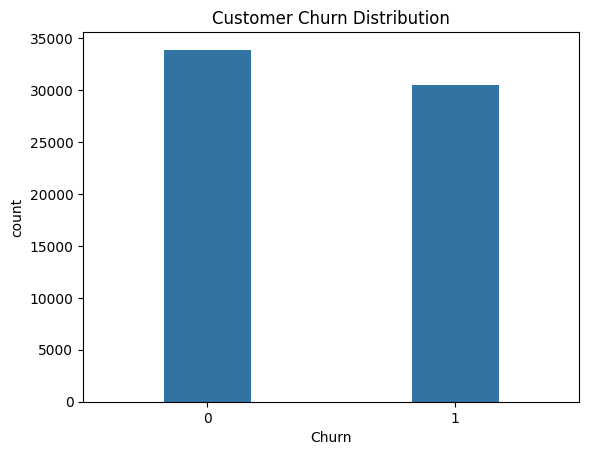

In [14]:
sns.countplot(data=df,x="Churn",width=0.35)
plt.title("Customer Churn Distribution")
plt.show()

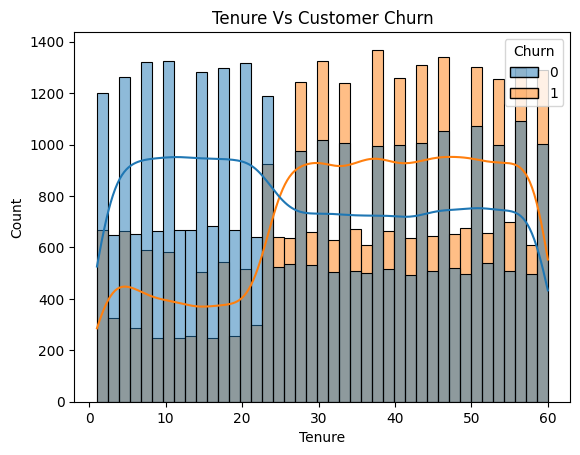

In [15]:
sns.histplot(data=df,x="Tenure",hue="Churn",kde=True)
plt.title("Tenure Vs Customer Churn")
plt.show()

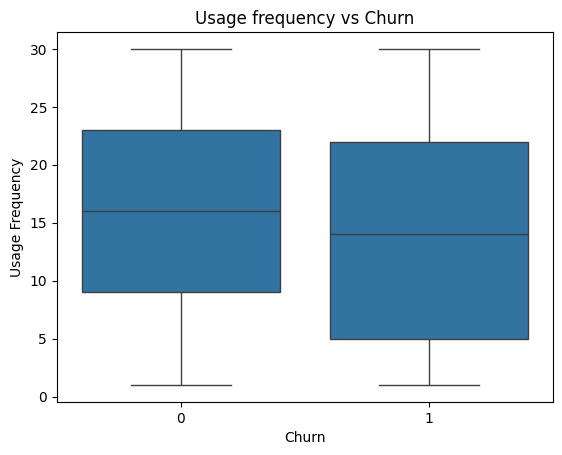

In [16]:
sns.boxplot(data=df, x="Churn", y="Usage Frequency")
plt.title("Usage frequency vs Churn")
plt.show()

In [17]:
X=df.drop(["CustomerID","Churn"],axis=1)
y=df["Churn"]

In [18]:
numerical_cols=X.select_dtypes(include='number').columns

In [19]:
categorical_cols=X.select_dtypes(include='object').columns

In [20]:
numerical_cols

Index(['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay',
       'Total Spend', 'Last Interaction'],
      dtype='object')

In [21]:
for col in categorical_cols:
    print("\n",col)
    print(df[col].value_counts())


 Gender
Gender
Female    34353
Male      30021
Name: count, dtype: int64

 Subscription Type
Subscription Type
Standard    21502
Basic       21451
Premium     21421
Name: count, dtype: int64

 Contract Length
Contract Length
Monthly      22130
Annual       21410
Quarterly    20834
Name: count, dtype: int64


In [22]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [23]:
from sklearn.preprocessing import StandardScaler
X_train = pd.get_dummies( X_train,columns=categorical_cols,dtype=int)
X_test = pd.get_dummies(X_test,columns=categorical_cols,dtype=int)

In [24]:
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [25]:
scaler=StandardScaler()
X_train[numerical_cols]=scaler.fit_transform(
    X_train[numerical_cols])
X_test[numerical_cols]=scaler.transform(X_test[numerical_cols])

In [26]:
X_train

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Gender_Female,Gender_Male,Subscription Type_Basic,Subscription Type_Premium,Subscription Type_Standard,Contract Length_Annual,Contract Length_Monthly,Contract Length_Quarterly
17402,1.002290,0.467698,-0.347864,-1.413220,-1.935572,0.728167,0.984201,1,0,0,0,1,0,1,0
20461,-0.289317,-0.117619,-1.254923,-0.448905,-0.918315,-1.387161,-1.100821,1,0,0,0,1,1,0,0
63787,-1.437413,-0.117619,0.672577,0.836848,0.211971,0.670685,-1.564159,0,1,0,1,0,0,0,1
12218,0.212974,-1.171191,1.239489,1.479724,-0.805286,1.759006,1.563374,0,1,0,1,0,0,1,0
6831,1.217558,0.292103,-0.234481,0.193971,0.551057,0.712838,-1.100821,1,0,0,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23727,1.002290,-0.293215,0.899342,0.836848,-0.692257,0.678349,-1.679994,1,0,1,0,0,1,0,0
52977,-0.074049,-1.756509,-1.481687,0.836848,0.438028,0.134189,0.405028,0,1,1,0,0,0,1,0
38437,-0.719853,-0.527342,1.352871,0.515410,-1.031343,-0.195373,-0.984986,1,0,1,0,0,0,1,0
42975,0.499998,-1.054128,0.105666,-1.734658,1.342257,-1.207052,-0.984986,1,0,1,0,0,0,0,1


In [27]:
X_train.shape

(51499, 15)

In [28]:
model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

In [29]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,185 (4.63 KB)

 Trainable params: 1,185 (4.63 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
print("Input Shape:",X_train.shape)
model.summary()
print("Target Values:",y_train.unique())

Input Shape: (51499, 15)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,185 (4.63 KB)

 Trainable params: 1,185 (4.63 KB)

 Non-trainable params: 0 (0.00 B)

Target Values: [0 1]


In [31]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [32]:
from tensorflow.keras import callbacks
from tensorflow.keras.callbacks import EarlyStopping
early_stop=keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True)

In [33]:
history=model.fit(
    X_train,y_train,epochs=100,batch_size=32,validation_split=0.2,callbacks=[early_stop],verbose=1)

Epoch 1/100
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8633 - loss: 0.3052 - val_accuracy: 0.9135 - val_loss: 0.1984
Epoch 2/100
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9329 - loss: 0.1647 - val_accuracy: 0.9430 - val_loss: 0.1387
Epoch 3/100
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9498 - loss: 0.1235 - val_accuracy: 0.9540 - val_loss: 0.1096
Epoch 4/100
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9582 - loss: 0.1022 - val_accuracy: 0.9616 - val_loss: 0.0945
Epoch 5/100
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9635 - loss: 0.0881 - val_accuracy: 0.9652 - val_loss: 0.0880
Epoch 6/100
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9679 - loss: 0.0786 - val_accuracy: 0.9662 - val_loss: 0.0786
Epoch 7/100
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9710 - loss: 0.0704 - val_accuracy: 0.9719 - val_loss: 0.0685
Epoch 8/100
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9728 - loss: 0

In [34]:
print(y.value_counts())
print(y.value_counts(normalize=True) * 100)

Churn
0    33881
1    30493
Name: count, dtype: int64
Churn
0    52.631497
1    47.368503
Name: proportion, dtype: float64


In [35]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

403/403 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9874 - loss: 0.0310
Test Loss: 0.030999142676591873
Test Accuracy: 0.987417459487915


In [36]:
from sklearn.metrics import classification_report
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int).ravel()
print(classification_report(y_test, y_pred))

403/403 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      6776
           1       0.99      0.99      0.99      6099

    accuracy                           0.99     12875
   macro avg       0.99      0.99      0.99     12875
weighted avg       0.99      0.99      0.99     12875



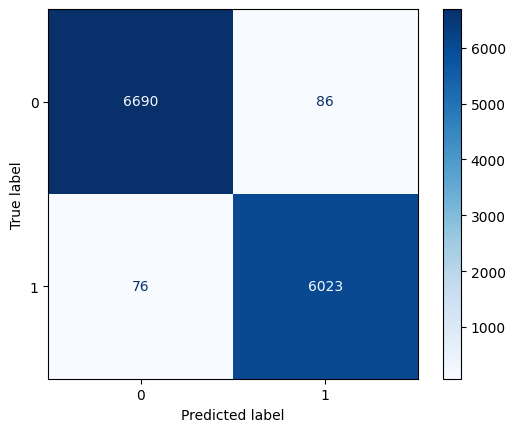

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.show()

In [38]:
correlation = df.corr(numeric_only=True)["Churn"].sort_values(
    ascending=False
)
print(correlation)

Churn               1.000000
Payment Delay       0.557386
CustomerID          0.529832
Support Calls       0.304631
Tenure              0.195327
Age                 0.063457
Last Interaction   -0.002818
Total Spend        -0.078867
Usage Frequency    -0.115098
Name: Churn, dtype: float64


In [39]:
train_features = X_train.copy()
test_features = X_test.copy()
print( "Overlapping records:",len(train_features.merge(test_features,how="inner")))

Overlapping records: 0


In [40]:
categorical_cols = ["Gender", "Subscription Type", "Contract Length"]
for col in categorical_cols:
    print(f"\n{col}")
    print(pd.crosstab(df[col], df["Churn"], normalize="index") * 100)


Gender
Churn           0          1
Gender                      
Female  44.950950  55.049050
Male    61.420339  38.579661

Subscription Type
Churn                      0          1
Subscription Type                      
Basic              51.722530  48.277470
Premium            53.503571  46.496429
Standard           52.669519  47.330481

Contract Length
Churn                    0          1
Contract Length                      
Annual           53.783279  46.216721
Monthly          48.391324  51.608676
Quarterly        55.951810  44.048190


In [41]:
print(df["Payment Delay"].describe())
print("\nSupport Calls:")
print(df["Support Calls"].describe())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

count    64374.000000
mean        17.133952
std          8.852211
min          0.000000
25%         10.000000
50%         19.000000
75%         25.000000
max         30.000000
Name: Payment Delay, dtype: float64

Support Calls:
count    64374.000000
mean         5.400690
std          3.114005
min          0.000000
25%          3.000000
50%          6.000000
75%          8.000000
max         10.000000
Name: Support Calls, dtype: float64

Churn distribution:
Churn
0    33881
1    30493
Name: count, dtype: int64


In [42]:
print(df.groupby(["Payment Delay", "Support Calls"])["Churn"].mean().sort_values(ascending=False).head(15))

Payment Delay  Support Calls
21             7                0.925170
29             6                0.923333
25             9                0.921053
30             8                0.914754
23             6                0.912892
22             6                0.912727
21             5                0.912621
22             10               0.912052
23             5                0.910345
21             9                0.910072
29             9                0.909420
25             7                0.908784
27             10               0.906810
26             6                0.905405
23             8                0.904412
Name: Churn, dtype: float64


In [43]:
for col in ["Payment Delay", "Support Calls", "Tenure"]:
    print(f"\n{col}")
    print(
        df.groupby(col)["Churn"]
        .agg(["mean", "count"])
        .sort_values("mean", ascending=False)
        .head(10)
    )


Payment Delay
                   mean  count
Payment Delay                 
23             0.778351   2716
21             0.772234   2766
30             0.770728   2774
29             0.769651   2748
25             0.767709   2781
26             0.763394   2781
27             0.762243   2818
22             0.761787   2821
24             0.757278   2748
28             0.756420   2726

Support Calls
                   mean  count
Support Calls                 
7              0.617821   6599
8              0.609565   6649
9              0.609094   6664
10             0.606953   6587
6              0.606115   6639
5              0.604627   6657
4              0.318376   5148
3              0.248359   4723
0              0.242199   4967
2              0.231505   4812

Tenure
            mean  count
Tenure                 
37      0.586122   1225
30      0.580699   1202
55      0.579122   1207
49      0.576300   1173
43      0.575439   1140
41      0.574910   1108
59      0.573477   1116
38

In [44]:
print(df.head(10))
print(df.dtypes)

   CustomerID  Age  Gender  Tenure  Usage Frequency  Support Calls  \
0           1   22  Female      25               14              4   
1           2   41  Female      28               28              7   
2           3   47    Male      27               10              2   
3           4   35    Male       9               12              5   
4           5   53  Female      58               24              9   
5           6   30    Male      41               14             10   
6           7   47  Female      37               15              9   
7           8   54  Female      36               11              0   
8           9   36    Male      20                5             10   
9          10   65    Male       8                4              2   

   Payment Delay Subscription Type Contract Length  Total Spend  \
0             27             Basic         Monthly          598   
1             13          Standard         Monthly          584   
2             29           P

In [45]:
print(df["CustomerID"].corr(df["Churn"]))

0.5298315536981301
